In [ ]:
import shutil
import os
import zipfile
from pathlib import Path

#Merge datasets
SOURCE_DIRS = {
    "Tumour" : ["/content/Mri_clean_224x224_tumor.zip"],
    "Stroke" : ["/content/Mri_clean_224x224_stroke.zip"],
    "Normal" : ["/content/Mri_clean_224x224_normal.zip"],
}
DEST = Path("brain_mri_combined")

# Ensure clean target directory
if DEST.exists():
    shutil.rmtree(DEST)
DEST.mkdir(parents=True, exist_ok=True)

for label, sources in SOURCE_DIRS.items():
    dest_class = DEST / label
    dest_class.mkdir(parents=True, exist_ok=True)
    for src in sources:
        if zipfile.is_zipfile(src):
            with zipfile.ZipFile(src, 'r') as zip_ref:
                # Extract files directly to class subdirectory
                for file_info in zip_ref.infolist():
                    if not file_info.is_dir() and file_info.filename.lower().endswith(('.jpg', '.jpeg')):

                        orig_filename = Path(file_info.filename).name

                        if orig_filename:
                            new_name = f"{Path(src).stem}_{orig_filename}"
                            dest_file_path = dest_class / new_name
                            with zip_ref.open(file_info) as source_file, open(dest_file_path, 'wb') as target_file:
                                shutil.copyfileobj(source_file, target_file)
        else:
            print(f"Warning: {src} is not a valid zip file.")

print("Extraction and merging complete!")

Extraction and merging complete!


In [ ]:
#Data Split
import tensorflow as tf

DATA_DIR = "brain_mri_combined"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

#Load full dataset with 70% training and 30% temporary validation set
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.3,
    subset = "training",
    seed = SEED,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE
)
val_temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split = 0.3,
    subset = "validation",
    seed = SEED,
    image_size = IMG_SIZE,
    batch_size = BATCH_SIZE
)

#Further split the 30% temp set into validation and test (50/50)
val_batches = tf.data.experimental.cardinality(val_temp_ds)
test_ds = val_temp_ds.take(val_batches // 2)
val_ds = val_temp_ds.skip(val_batches // 2)

print(f"Class names: {train_ds.class_names}")
print(f"Training batches: {tf.data.experimental.cardinality(train_ds)}")
print(f"Validation batches: {tf.data.experimental.cardinality(val_ds)}")
print(f"Test batches: {tf.data.experimental.cardinality(test_ds)}")

Found 2895 files belonging to 3 classes.
Using 2027 files for training.
Found 2895 files belonging to 3 classes.
Using 868 files for validation.
Class names: ['Normal', 'Stroke', 'Tumour']
Training batches: 64
Validation batches: 14
Test batches: 14


In [ ]:
#Preprocess
AUTOTUNE = tf.data.AUTOTUNE

def preprocess(image, label):
    # Convert grayscale to RGB (replicate channels)
    #image = tf.image.grayscale_to_rgb(image)
    return image, label

train_ds = train_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_ds.map(preprocess, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

In [ ]:
#Augmentation
augment_layers = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(factor = 0.1)
])
def preprocess_with_augmentation(image, label):
    image = tf.image.random_brightness(image, 0.1)
    return image, label

In [ ]:
#EfficientNetB0 Model
from tensorflow.keras import layers, models, optimizers

base_model = tf.keras.applications.EfficientNetB0(
    include_top = False,
    weights = "imagenet",
    input_shape = (224, 224, 3),
    pooling = "avg"
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.Dropout(0.2),
    layers.Dense(3, activation="softmax")
])

model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#Class Imbalance:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

train_labels = np.concatenate([y for x, y in train_ds], axis=0)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_labels),
    y=train_labels
)
class_weight_dict = dict(enumerate(class_weights))

In [ ]:
#Train with Two-Stage Transfer Learning
#Stage 1: Feature extraction (backbone frozen)
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=3, restore_best_weights=True
    )]
)
#Stage 2: Fine-tuning (Unfreeze backbone)
base_model.trainable = True
model.compile(
    optimizer=optimizers.Adam(learning_rate=2e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=3, restore_best_weights=True
    )]
)
# Save the trained EfficientNet model
model.save("best_efficientnet.keras")
print("EfficientNet model saved successfully!")

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy: 0.8234 - loss: 0.4255 - val_accuracy: 0.7690 - val_loss: 0.5558
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 148ms/step - accuracy: 0.8569 - loss: 0.3560 - val_accuracy: 0.7762 - val_loss: 0.5357
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 152ms/step - accuracy: 0.8762 - loss: 0.3036 - val_accuracy: 0.7548 - val_loss: 0.5446
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step - accuracy: 0.8959 - loss: 0.2626 - val_accuracy: 0.7833 - val_loss: 0.4667
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 141ms/step - accuracy: 0.9211 - loss: 0.2285 - val_accuracy: 0.7595 - val_loss: 0.5055
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 140ms/step - accuracy: 0.9245 - loss: 0.2075 - val_accuracy: 0.8048 - val_loss: 0.4363
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.9324 - loss: 0.1812 - val_accuracy: 0.7667 - val_loss: 0.5170
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 9s 136ms/step - accuracy: 0.9393 - loss: 0.1774 - val_accuracy

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.8214 - loss: 0.4141

True Model.evaluate Test Accuracy: 82.14%

Aligned Test Accuracy: 82.59%


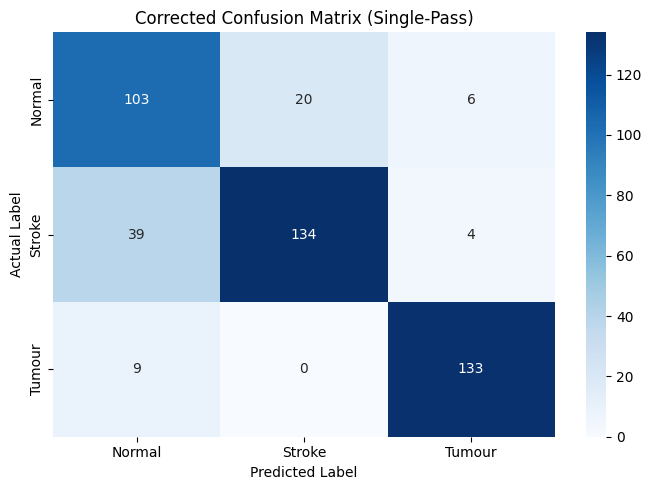


Corrected Classification Report:
              precision    recall  f1-score   support

      Normal       0.68      0.80      0.74       129
      Stroke       0.87      0.76      0.81       177
      Tumour       0.93      0.94      0.93       142

    accuracy                           0.83       448
   macro avg       0.83      0.83      0.83       448
weighted avg       0.83      0.83      0.83       448



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Explicitly define class names since prefetching removes the metadata attribute
class_names = ['Normal', 'Stroke', 'Tumour']

# Standard model evaluation directly on the dataset
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTrue Model.evaluate Test Accuracy: {test_acc * 100:.2f}%\n")

# Collect actuals and predictions in a single pass to ensure correct alignment
all_y_true = []
all_y_pred = []

for images, labels in test_ds:
    preds = model.predict_on_batch(images)
    pred_classes = np.argmax(preds, axis=1)

    all_y_true.extend(labels.numpy())
    all_y_pred.extend(pred_classes)

y_true_correct = np.array(all_y_true)
y_pred_correct = np.array(all_y_pred)

# Recalculate metrics
correct_accuracy = accuracy_score(y_true_correct, y_pred_correct)
print(f"Aligned Test Accuracy: {correct_accuracy * 100:.2f}%")

# Re-plot confusion matrix
cm_correct = confusion_matrix(y_true_correct, y_pred_correct)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_correct, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Corrected Confusion Matrix (Single-Pass)")
plt.tight_layout()
plt.show()

print("\nCorrected Classification Report:")
print(classification_report(y_true_correct, y_pred_correct, target_names=class_names))